# Классификация изображений с помощью CNN

Построим собственную CNN для шести классов Intel Image Classification. Сравним исходную модель и модель с аугментациями, проследим за переобучением по validation loss.

Разделим `seg_train` на обучающую (80%) и валидационную (20%) выборки. `seg_test` оставим для итоговой оценки после выбора модели. В Colab используем GPU, локально доступен CPU.


In [1]:
from pathlib import Path
import random

import torch
from torch import nn
from collections import Counter

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent


Устройство: cuda


## Датасет в Colab

Загрузим Intel Image Classification через kagglehub. При повторном запуске используется доступный кеш.


In [2]:
!pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print(dataset_path)

train_dir = Path(dataset_path) / "seg_train" / "seg_train"
print("Датасет найден:", train_dir.exists())

Using Colab cache for faster access to the 'intel-image-classification' dataset.
/kaggle/input/intel-image-classification
Датасет найден: True


## Данные и батчи

Преобразования применяются не меняют исходные файлы.

Стратифицированное разбиение сохранит доли классов. Зафиксируем SEED=42 для разбиения и перемешивания train, validation перемешивать не будем.

In [ ]:
# Все изображения к размеру 128 на 128, пиксели RGB - от 0 до 1 
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

# Нумеруем классы по названиям папок
dataset = datasets.ImageFolder(train_dir, transform=transform)
classes = dataset.classes

# Делим индексы с сохранением долей классов (stratify = y)
train_indices, val_indices = train_test_split(
    range(len(dataset)),
    test_size=0.2,
    stratify=dataset.targets,
    random_state=SEED,
)
train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

# Загружаем батчи по 32 изображени 
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,   # перемешиваем порядок изображений перед каждой эпохой
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,  # 0 доп.процессов
)

val_loader = DataLoader(
    val_dataset,    
    batch_size=32,
    shuffle=False,  # при оценке данные перемешивать не требуется
    num_workers=0
)

images, labels = next(iter(train_loader))
print("Классы:", ", ".join(classes))
print(f"Train: {len(train_dataset):,}, validation: {len(val_dataset):,}")
print("Батч изображений:", tuple(images.shape))
print("Батч меток:", tuple(labels.shape))
print("Оси изображений: (число снимков, каналы, высота, ширина)")


Классы: buildings, forest, glacier, mountain, sea, street
Train: 11,227, validation: 2,807
Батч изображений: (32, 3, 128, 128)
Батч меток: (32,)
Оси изображений: (число снимков, каналы, высота, ширина)


In [ ]:
# посмотрим доли классов
train_counts = Counter(dataset.targets[i] for i in train_indices)
val_counts = Counter(dataset.targets[i] for i in val_indices)

print(f"{'Класс':<12} {'Train':>7} {'Доля':>8} {'Validation':>11} {'Доля':>8}")
for class_id, class_name in enumerate(classes):
    train_count = train_counts[class_id]
    val_count = val_counts[class_id]
    print(
        f"{class_name:<12} {train_count:>7} {train_count / len(train_dataset):>8.1%} "
        f"{val_count:>11} {val_count / len(val_dataset):>8.1%}"
    )


Класс          Train     Доля  Validation     Доля
buildings       1753    15.6%         438    15.6%
forest          1817    16.2%         454    16.2%
glacier         1923    17.1%         481    17.1%
mountain        2009    17.9%         503    17.9%
sea             1819    16.2%         455    16.2%
street          1906    17.0%         476    17.0%


## Архитектура CNN

Три свёрточных блока выделяют признаки, два линейных слоя выдают оценки шести классов. Свёртка с `kernel_size=3` и `padding=1` сохраняет высоту и ширину.

`MaxPool2d(2)` выбирает максимум в окне 2×2 с шагом 2: пространственные размеры уменьшаются **128 → 64 → 32 → 16**. Перед линейными слоями разворачиваем 64 карты 16×16 в вектор из 16 384 значений.


In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), # 3 признака (RGB) - в 16 обучаемых фильтров
            nn.ReLU(),
            nn.MaxPool2d(2),                            # уменьшаем h и w в 2 раза
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.flatten = nn.Flatten()                     # признаки - в вектор
        self.classifier = nn.Sequential(
            nn.Linear(64 * 16 * 16, 128),               # cжимаем вектор из 16384 признаков до 128
            nn.ReLU(),
            nn.Linear(128, 6),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.flatten(x)
        return self.classifier(x)


model = SimpleCNN().to(device)

In [ ]:
# посмотрим форму тензора без вычисления градиентов
with torch.no_grad():
    x = images[:1].to(device)
    print("Вход:      ", tuple(x.shape))
    x = model.block1(x)
    print("Блок 1:   ", tuple(x.shape))
    x = model.block2(x)
    print("Блок 2:   ", tuple(x.shape))
    x = model.block3(x)
    print("Блок 3:   ", tuple(x.shape))
    x = model.flatten(x)
    print("Flatten:  ", tuple(x.shape))
    x = model.classifier(x)
    print("Выход:    ", tuple(x.shape))


Вход:       (1, 3, 128, 128)
Блок 1:    (1, 16, 64, 64)
Блок 2:    (1, 32, 32, 32)
Блок 3:    (1, 64, 16, 16)
Flatten:   (1, 16384)
Выход:     (1, 6)


## Функция потерь и первый прогноз

`CrossEntropyLoss` принимает логиты и числовые метки классов, используем его для многоклассовой классификации. Отдельный Softmax не нужен: log-softmax уже входит в вычисление потерь.

Используем Adam со скоростью обучения `0.001`.


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

 # режим оценки
model.eval()

with torch.no_grad():
    logits = model(images.to(device))
    loss = criterion(logits, labels.to(device))

print("Размер логитов:", tuple(logits.shape))  # 32 снимка × 6 классов
print(f"Loss до обучения: {loss.item():.4f}")


Размер логитов: (32, 6)
Loss до обучения: 1.7786


## Цикл обучения и короткая проверка

В `train_one_epoch` обновляем веса, в `evaluate` оцениваем модель без градиентов. Loss и accuracy усредняем по обработанным изображениям.

Мини-проверка ограничена десятью батчами каждой выборки. Она проверяет работу кода, а не итоговое качество; повторный запуск продолжает обучение текущих весов.


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device, max_batches=None):
    # режим обучения
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_number, (images, labels) in enumerate(loader, start=1):
        # модель и данные должны находиться на одном устройстве.
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()               # обнуляем градиенты
        logits = model(images)              # прямой проход, получаем logits 
        loss = criterion(logits, labels)    # считаем ошибку
        loss.backward()                     # вычисляем градиенты весов
        optimizer.step()                    # обновляем параметры

        # Взвешиваем loss по размеру батча: последний может быть меньше
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
        if max_batches is not None and batch_number >= max_batches:
            break

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device, max_batches=None):
    # режим оценки
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_number, (images, labels) in enumerate(loader, start=1):
            images = images.to(device)
            labels = labels.to(device)
            
            logits = model(images)              # получаем предсказания без обновления параметров модели
            loss = criterion(logits, labels)    # ошибка на validation

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
            if max_batches is not None and batch_number >= max_batches:
                break

    return total_loss / total, correct / total  # средняя ошибка и accuracy на обработанной выборке


In [9]:
MAX_BATCHES = 10

train_loss, train_accuracy = train_one_epoch(
    model, train_loader, criterion, optimizer, device, max_batches=MAX_BATCHES,
)
val_loss, val_accuracy = evaluate(
    model, val_loader, criterion, device, max_batches=MAX_BATCHES,
)

print(f"Train      | loss: {train_loss:.4f} | accuracy: {train_accuracy:.1%}")
print(f"Validation | loss: {val_loss:.4f} | accuracy: {val_accuracy:.1%}")
print("Проверка завершена: обработано по 10 батчей train и validation.")


Train      | loss: 1.7695 | accuracy: 23.1%
Validation | loss: 1.6732 | accuracy: 39.7%
Проверка завершена: обработано по 10 батчей train и validation.


## Google Drive

Подключим Drive для сохранения весов и результатов между сессиями Colab.


In [10]:
from google.colab import drive
drive.mount("/content/drive")

save_dir = Path("/content/drive/MyDrive/image-classification/models")
save_dir.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Эксперимент 1: исходная CNN


Обучим новую модель в течение 15 эпох без аугментаций. Сохраним веса с минимальным validation loss в `best_cnn.pth`.


In [ ]:
# Начинаем обучение с нуля
model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 15

# История первого эксперимента
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}

best_val_loss = float("inf")
best_epoch = 0
best_model_path = save_dir / "best_cnn.pth"

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Выбираем веса по validation loss, а не по ошибке на train
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        torch.save({
            "model_state_dict": model.state_dict(),
            "classes": classes,
            "epoch": best_epoch,
            "val_loss": best_val_loss,
        }, best_model_path)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss: {train_loss:.4f}, acc: {train_acc:.1%} | "
        f"val loss: {val_loss:.4f}, acc: {val_acc:.1%}"
    )

print(f"\nЛучшая эпоха: {best_epoch}")
print(f"Модель сохранена: {best_model_path}")

Epoch 01/15 | train loss: 1.0425, acc: 59.5% | val loss: 0.8607, acc: 66.3%
Epoch 02/15 | train loss: 0.7536, acc: 71.4% | val loss: 0.7085, acc: 73.6%
Epoch 03/15 | train loss: 0.5938, acc: 78.0% | val loss: 0.7179, acc: 73.2%
Epoch 04/15 | train loss: 0.5021, acc: 81.6% | val loss: 0.6400, acc: 76.4%
Epoch 05/15 | train loss: 0.3885, acc: 85.5% | val loss: 0.6576, acc: 77.1%
Epoch 06/15 | train loss: 0.2938, acc: 89.6% | val loss: 0.6681, acc: 78.9%
Epoch 07/15 | train loss: 0.2088, acc: 92.7% | val loss: 0.7645, acc: 78.2%
Epoch 08/15 | train loss: 0.1617, acc: 94.6% | val loss: 0.8176, acc: 78.0%
Epoch 09/15 | train loss: 0.0999, acc: 96.6% | val loss: 1.0561, acc: 77.8%
Epoch 10/15 | train loss: 0.0747, acc: 97.7% | val loss: 1.0871, acc: 78.3%
Epoch 11/15 | train loss: 0.0593, acc: 98.2% | val loss: 1.1946, acc: 78.2%
Epoch 12/15 | train loss: 0.0517, acc: 98.4% | val loss: 1.3501, acc: 75.4%
Epoch 13/15 | train loss: 0.0410, acc: 98.8% | val loss: 1.3865, acc: 77.8%
Epoch 14/15 

### Кривые обучения исходной CNN

Сравним train и validation loss и accuracy по эпохам.


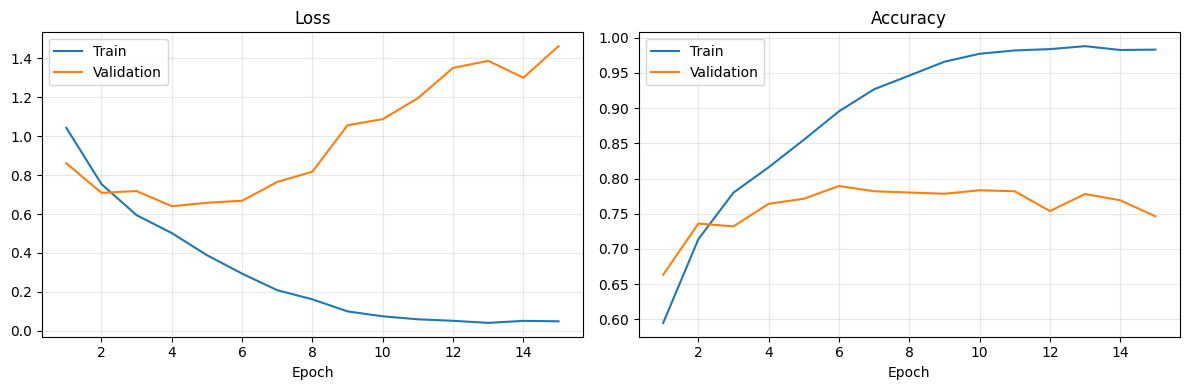

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_acc"], label="Train")
axes[1].plot(epochs, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Эксперимент 2: аугментации и early stopping

В первом эксперименте train loss снижался, а validation loss рос к концу обучения - признак переобучения.

Добавим случайные отражения и повороты только для train. Сохраним архитектуру, разбиение, batch size 32, Adam (`lr=0.001`) и CrossEntropyLoss. Остановим обучение после четырёх эпох без снижения validation loss.


In [ ]:
# Отдельные transforms: случайные изменения только в train
train_transform_augmented = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])

val_transform_augmented = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_images_augmented = datasets.ImageFolder(train_dir, transform=train_transform_augmented)
val_images_augmented = datasets.ImageFolder(train_dir, transform=val_transform_augmented)

# Те же индексы исключают влияние нового разбиения на сравнение.
train_dataset_augmented = Subset(train_images_augmented, train_indices)
val_dataset_augmented = Subset(val_images_augmented, val_indices)

train_loader_augmented = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
)

val_loader_augmented = DataLoader(
    val_dataset_augmented, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0,
)

print(f"Train: {len(train_dataset_augmented):,}, validation: {len(val_dataset_augmented):,}")

Train: 11,227, validation: 2,807


### Обучение с аугментациями

Начнём с новых весов и нового состояния Adam. Лимит - 15 эпох, `patience=4`. Запуск по умолчанию выключен.

Лучшие веса и история сохраняются на Drive в `models/best_cnn_augmented.pth`. Результаты исходной CNN остаются в `best_cnn.pth` и `history`; повторный запуск обновляет только результаты второго эксперимента. Графики сохраняются рядом с весами в `cnn_augmented_curves.png`.


In [ ]:
RUN_AUGMENTED_TRAINING = True  # True — запуск обучения в Colab с GPU.

# Новые модель и Adam исключают продолжение обучения baseline
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

model_augmented = SimpleCNN().to(device)
criterion_augmented = nn.CrossEntropyLoss()
optimizer_augmented = torch.optim.Adam(model_augmented.parameters(), lr=0.001)

# Восстанавливаем порядок батчей и при повторном запуске этой ячейки
train_loader_augmented.generator.manual_seed(SEED)

history_augmented = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_loss_augmented = float("inf")
best_epoch_augmented = 0
patience = 4
epochs_without_improvement = 0
EPOCHS_AUGMENTED = 15

best_model_path_augmented = Path(
    "/content/drive/MyDrive/image-classification/models/best_cnn_augmented.pth"
)

if RUN_AUGMENTED_TRAINING:
    if device.type != "cuda":
        raise RuntimeError("Для полного обучения выберите GPU в Colab.")
    if not Path("/content/drive/MyDrive").is_dir():
        raise RuntimeError("Google Drive не подключён.")
    best_model_path_augmented.parent.mkdir(parents=True, exist_ok=True)

    for epoch in range(1, EPOCHS_AUGMENTED + 1):
        train_loss_aug, train_acc_aug = train_one_epoch(
            model_augmented, train_loader_augmented,
            criterion_augmented, optimizer_augmented, device,
        )

        val_loss_aug, val_acc_aug = evaluate(
            model_augmented, val_loader_augmented, criterion_augmented, device,
        )

        history_augmented["train_loss"].append(train_loss_aug)
        history_augmented["val_loss"].append(val_loss_aug)
        history_augmented["train_acc"].append(train_acc_aug)
        history_augmented["val_acc"].append(val_acc_aug)

        # Сохраняем лучшую эпоху по validation loss для выбора модели
        if val_loss_aug < best_val_loss_augmented:
            best_val_loss_augmented = val_loss_aug
            best_epoch_augmented = epoch
            epochs_without_improvement = 0
            torch.save({
                "model_state_dict": model_augmented.state_dict(),
                "classes": classes,
                "epoch": epoch,
                "val_loss": val_loss_aug,
                "val_acc": val_acc_aug,
            }, best_model_path_augmented)
        else:
            # Счётчик сбрасывается только при снижении validation loss
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:02d}/{EPOCHS_AUGMENTED} | "
            f"train loss: {train_loss_aug:.4f}, acc: {train_acc_aug:.1%} | "
            f"val loss: {val_loss_aug:.4f}, acc: {val_acc_aug:.1%}"
        )
        # Четыре эпохи подряд без улучшения завершают обучение.
        if epochs_without_improvement >= patience:
            print(f"Early stopping: {patience} эпох без улучшения validation loss.")
            break

    # Сохраняем всю историю в том же файле, сохраняя веса лучшей эпохи.
    checkpoint_augmented = torch.load(
        best_model_path_augmented, map_location="cpu", weights_only=True,
    )
    checkpoint_augmented["history_augmented"] = history_augmented
    torch.save(checkpoint_augmented, best_model_path_augmented)
    print(f"Лучшая эпоха: {best_epoch_augmented}; loss: {best_val_loss_augmented:.4f}")
    print("Сохранено:", best_model_path_augmented)
else:
    print("Обучение выключено. Для запуска в Colab задайте RUN_AUGMENTED_TRAINING = True.")


Epoch 01/15 | train loss: 1.0532, acc: 58.9% | val loss: 0.8803, acc: 65.8%
Epoch 02/15 | train loss: 0.8035, acc: 69.6% | val loss: 0.7455, acc: 71.9%
Epoch 03/15 | train loss: 0.6686, acc: 75.5% | val loss: 0.6158, acc: 78.0%
Epoch 04/15 | train loss: 0.5832, acc: 78.2% | val loss: 0.6219, acc: 77.3%
Epoch 05/15 | train loss: 0.5214, acc: 80.4% | val loss: 0.5208, acc: 82.3%
Epoch 06/15 | train loss: 0.4875, acc: 81.7% | val loss: 0.7260, acc: 75.1%
Epoch 07/15 | train loss: 0.4606, acc: 82.9% | val loss: 0.5247, acc: 81.5%
Epoch 08/15 | train loss: 0.4182, acc: 84.4% | val loss: 0.5755, acc: 79.7%
Epoch 09/15 | train loss: 0.3886, acc: 85.7% | val loss: 0.5190, acc: 81.5%
Epoch 10/15 | train loss: 0.3650, acc: 86.3% | val loss: 0.4978, acc: 83.4%
Epoch 11/15 | train loss: 0.3261, acc: 87.7% | val loss: 0.5334, acc: 82.4%
Epoch 12/15 | train loss: 0.3043, acc: 88.5% | val loss: 0.5496, acc: 81.5%
Epoch 13/15 | train loss: 0.2844, acc: 89.3% | val loss: 0.5026, acc: 82.8%
Epoch 14/15 

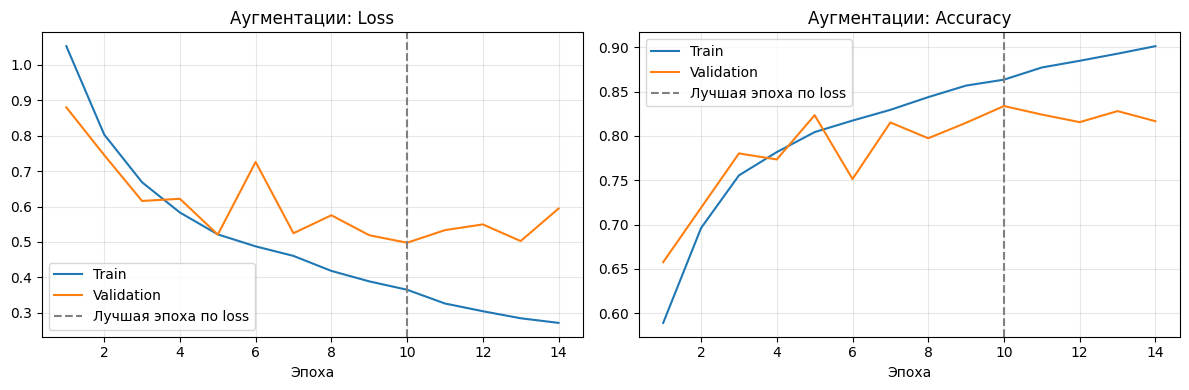

Графики сохранены: /content/drive/MyDrive/image-classification/models/cnn_augmented_curves.png


In [13]:
import matplotlib.pyplot as plt

if history_augmented["val_loss"]:
    epochs_augmented = range(1, len(history_augmented["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, train_key, val_key, title in zip(
        axes, ["train_loss", "train_acc"], ["val_loss", "val_acc"], ["Loss", "Accuracy"],
    ):
        ax.plot(epochs_augmented, history_augmented[train_key], label="Train")
        ax.plot(epochs_augmented, history_augmented[val_key], label="Validation")
        ax.axvline(best_epoch_augmented, color="gray", linestyle="--", label="Лучшая эпоха по loss")
        ax.set_title(f"Аугментации: {title}")
        ax.set_xlabel("Эпоха")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plot_path_augmented = best_model_path_augmented.parent / "cnn_augmented_curves.png"
    fig.savefig(plot_path_augmented, dpi=150, bbox_inches="tight")
    plt.show()
    print("Графики сохранены:", plot_path_augmented)
else:
    print("Графики появятся после обучения второго эксперимента.")


### Сравнение с исходной CNN

Метрики baseline взяты из предыдущего запуска: loss **0.6400** и accuracy **76.4%** на эпохе 4, максимальная accuracy **78.9%** на эпохе 6. Полную историю по этим значениям не восстанавливаем.

Сравним минимальный validation loss и accuracy на той же эпохе; максимальную accuracy покажем отдельно. Вывод о влиянии аугментаций сделаем после второго эксперимента. Test на этом этапе не используем.


In [14]:
# Итоговые метрики из предыдущего запуска baseline, без восстановления истории.
baseline_summary = {
    "best_val_loss": 0.6400,
    "best_epoch": 4,
    "accuracy_at_best_loss": 0.764,
    "max_val_accuracy": 0.789,
    "max_accuracy_epoch": 6,
}
print(f"{'Эксперимент':<16} {'Min val loss':>13} {'Эпоха':>7} {'Acc при min loss':>18} {'Max val acc':>13}")
print(
    f"{'Baseline':<16} {baseline_summary['best_val_loss']:>13.4f} "
    f"{baseline_summary['best_epoch']:>7} {baseline_summary['accuracy_at_best_loss']:>18.1%} "
    f"{baseline_summary['max_val_accuracy']:>13.1%}"
)
if history_augmented["val_loss"]:
    best_index_augmented = history_augmented["val_loss"].index(min(history_augmented["val_loss"]))
    accuracy_at_best_loss_augmented = history_augmented["val_acc"][best_index_augmented]
    print(
        f"{'Аугментации':<16} {min(history_augmented['val_loss']):>13.4f} "
        f"{best_index_augmented + 1:>7} {accuracy_at_best_loss_augmented:>18.1%} "
        f"{max(history_augmented['val_acc']):>13.1%}"
    )
else:
    print("Аугментации: эксперимент ещё не выполнен.")


Эксперимент       Min val loss   Эпоха   Acc при min loss   Max val acc
Baseline                0.6400       4              76.4%         78.9%
Аугментации             0.4978      10              83.4%         83.4%
